In [ ]:
!pip install xgboost
!pip install catboost lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.0 MB/s eta 0:00:00


In [ ]:
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import warnings
warnings.filterwarnings('ignore')


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.manifold import TSNE

colorarr = ['#0592D0','#Cd7f32', '#E97451', '#Bdb76b', '#954535', '#C2b280', '#808000','#C2b280', '#E4d008', '#9acd32', '#Eedc82', '#E4d96f',
           '#32cd32','#39ff14','#00ff7f', '#008080', '#36454f', '#F88379', '#Ff4500', '#Ffb347', '#A94064', '#E75480', '#Ffb6c1', '#E5e4e2',
           '#Faf0e6', '#8c92ac', '#Dbd7d2','#A7a6ba', '#B38b6d']

In [ ]:
DataSet = pd.read_csv("/content/NewDataSet Only New Category Added.csv")

In [ ]:
DataSet

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43.0,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41.0,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44.0,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40.0,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42.0,20.130175,81.604873,7.628473,262.717340,rice
...,...,...,...,...,...,...,...,...
2300,25,33,35.0,27.150000,50.320000,5.670000,178.000000,jack_fruit
2301,18,30,33.0,28.970000,38.550000,5.190000,182.000000,jack_fruit
2302,8,31,48.0,27.700000,49.120000,5.290000,177.000000,jack_fruit
2303,36,37,38.0,27.010000,51.090000,5.130000,180.000000,jack_fruit


In [ ]:
DataSet.shape

(2305, 8)

In [ ]:
print("Number of various crops: ", len(DataSet['label'].unique()))
print("List of crops: ", DataSet['label'].unique())

Number of various crops:  23
List of crops:  ['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee' 'jack_fruit']


In [ ]:
DataSet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2305 entries, 0 to 2304
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2305 non-null   int64  
 1   P            2305 non-null   int64  
 2   K            2305 non-null   float64
 3   temperature  2305 non-null   float64
 4   humidity     2305 non-null   float64
 5   ph           2305 non-null   float64
 6   rainfall     2305 non-null   float64
 7   label        2305 non-null   object 
dtypes: float64(5), int64(2), object(1)
memory usage: 144.2+ KB


In [ ]:
DataSet.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2305.000000,2305.000000,2305.000000,2305.000000,2305.000000,2305.000000,2305.000000
mean,49.589588,52.643818,47.893511,25.744316,70.576209,6.433006,107.029510
std,36.371932,32.437698,49.515823,5.001264,22.167951,0.788305,56.136239
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,29.000000,21.000000,22.954582,56.734265,5.931538,65.628595
50%,36.000000,49.000000,33.000000,25.787498,79.796094,6.402926,97.768323
75%,83.000000,67.000000,48.000000,28.660863,89.396555,6.893509,141.483164
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [ ]:
# Check Null Value
DataSet.isnull().any()

,0
N,False
P,False
K,False
temperature,False
humidity,False
ph,False
rainfall,False
label,False


In [ ]:
DataSet['label'].value_counts()

,count
label,
jack_fruit,105
maize,100
rice,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
chickpea,100
mungbean,100
blackgram,100


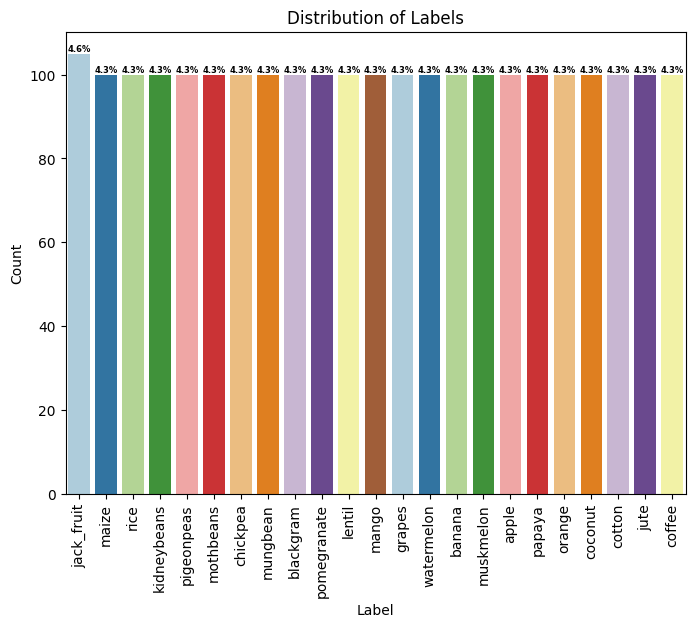

In [ ]:
# Get value counts
value_counts = DataSet['label'].value_counts()

# Calculate percentages
percentages = (value_counts / value_counts.sum()) * 100

# Set the size of the plot
plt.figure(figsize=(8, 6))

# Create a Seaborn bar plot
ax = sns.barplot(x=value_counts.index, y=value_counts.values, palette='Paired')

# Add percentage on top of each bar
for i, v in enumerate(value_counts):
    ax.text(i, v + 0.5, f"{percentages[i]:.1f}%", ha='center', fontsize=6, fontweight='bold')

# Add labels and title
plt.title('Distribution of Labels')
plt.xlabel('Label')
plt.ylabel('Count')
plt.xticks(rotation=90)

# Save the figure
plt.savefig('label_distribution.png', dpi=300, bbox_inches='tight')

# Show the plot
plt.show();

In [ ]:
crop_summary = pd.pivot_table(DataSet,index=['label'],aggfunc='mean')
crop_summary.head()

,K,N,P,humidity,ph,rainfall,temperature
label,,,,,,,
apple,199.89,20.80,134.22,92.333383,5.929663,112.654779,22.630942
banana,50.05,100.23,82.01,80.358123,5.983893,104.626980,27.376798
blackgram,19.24,40.02,67.47,65.118426,7.133952,67.884151,29.973340
chickpea,79.92,40.09,67.79,16.860439,7.336957,80.058977,18.872847
coconut,30.59,21.98,16.93,94.844272,5.976562,175.686646,27.409892


In [ ]:
X = DataSet.iloc[:,:7]
label = DataSet['label']

X_train, X_test, y_train, y_test = train_test_split(X, label, train_size=0.8,random_state=42, stratify=label)

In [ ]:
# balanced data, also after spliting to train and test
y_train.value_counts()

,count
label,
jack_fruit,84
banana,80
mango,80
blackgram,80
apple,80
maize,80
muskmelon,80
papaya,80
mungbean,80


In [ ]:
# defining variables for future use
features = X_train.columns
train = pd.concat([X_train, y_train], axis=1)

In [ ]:
from collections import Counter

def detect_outliers(df, n, features):
    outlier_indices = []

    for col in features:
        Q1 = np.percentile(df[col], 25)
        Q3 = np.percentile(df[col], 75)
        IQR = Q3 - Q1

        outlier_step = 1.5 * IQR

        outlier_list_col = df[(df[col] < Q1 - outlier_step) | (df[col] > Q3 + outlier_step )].index

        outlier_indices.extend(outlier_list_col)

    outlier_indices_counter = Counter(outlier_indices)
    multiple_outliers = [ k for k, v in outlier_indices_counter.items() if v > n]

    return multiple_outliers, outlier_indices

In [ ]:
outliers_to_drop, outliers = detect_outliers(X_train, 2, features)
print(f"{len(outliers)} samples contain outliers, {len(outliers_to_drop)} of them are outliers in more then two features.")

431 samples contain outliers, 17 of them are outliers in more then two features.


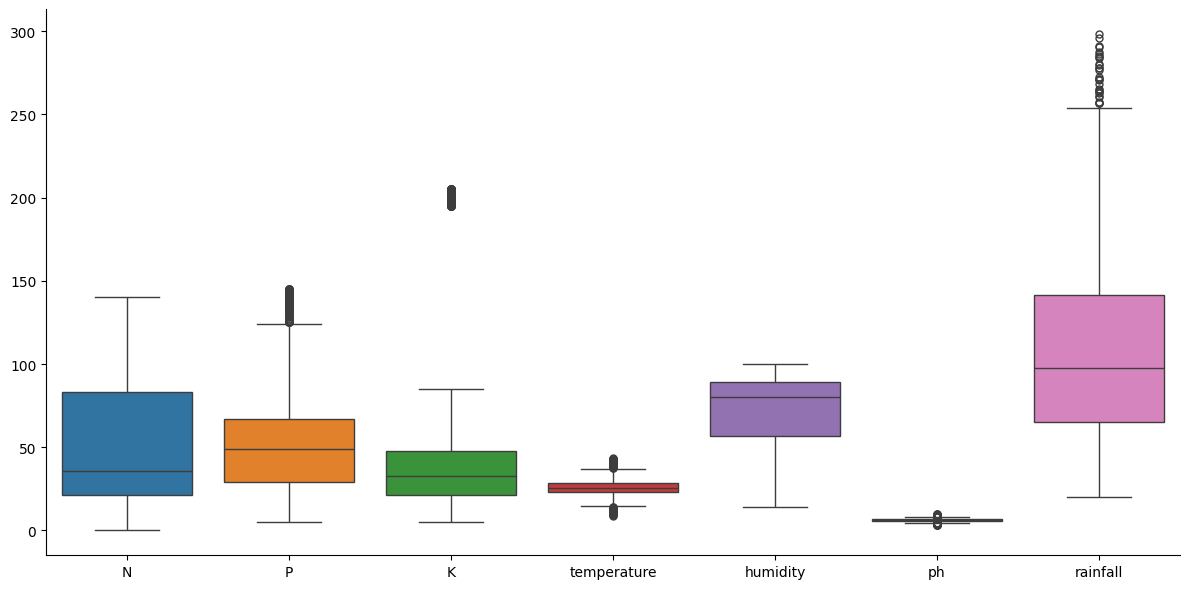

In [ ]:
#X_train[X_train.columns].boxplot()
# Create box plots for all columns
g = sns.catplot(
    data=X_train,
    kind="box",
    height=6,
    aspect=2
)
# Adjust layout
g.fig.tight_layout()

# Save figure
g.savefig("boxplot.png", dpi=300, bbox_inches="tight")

# Show plot
plt.show()

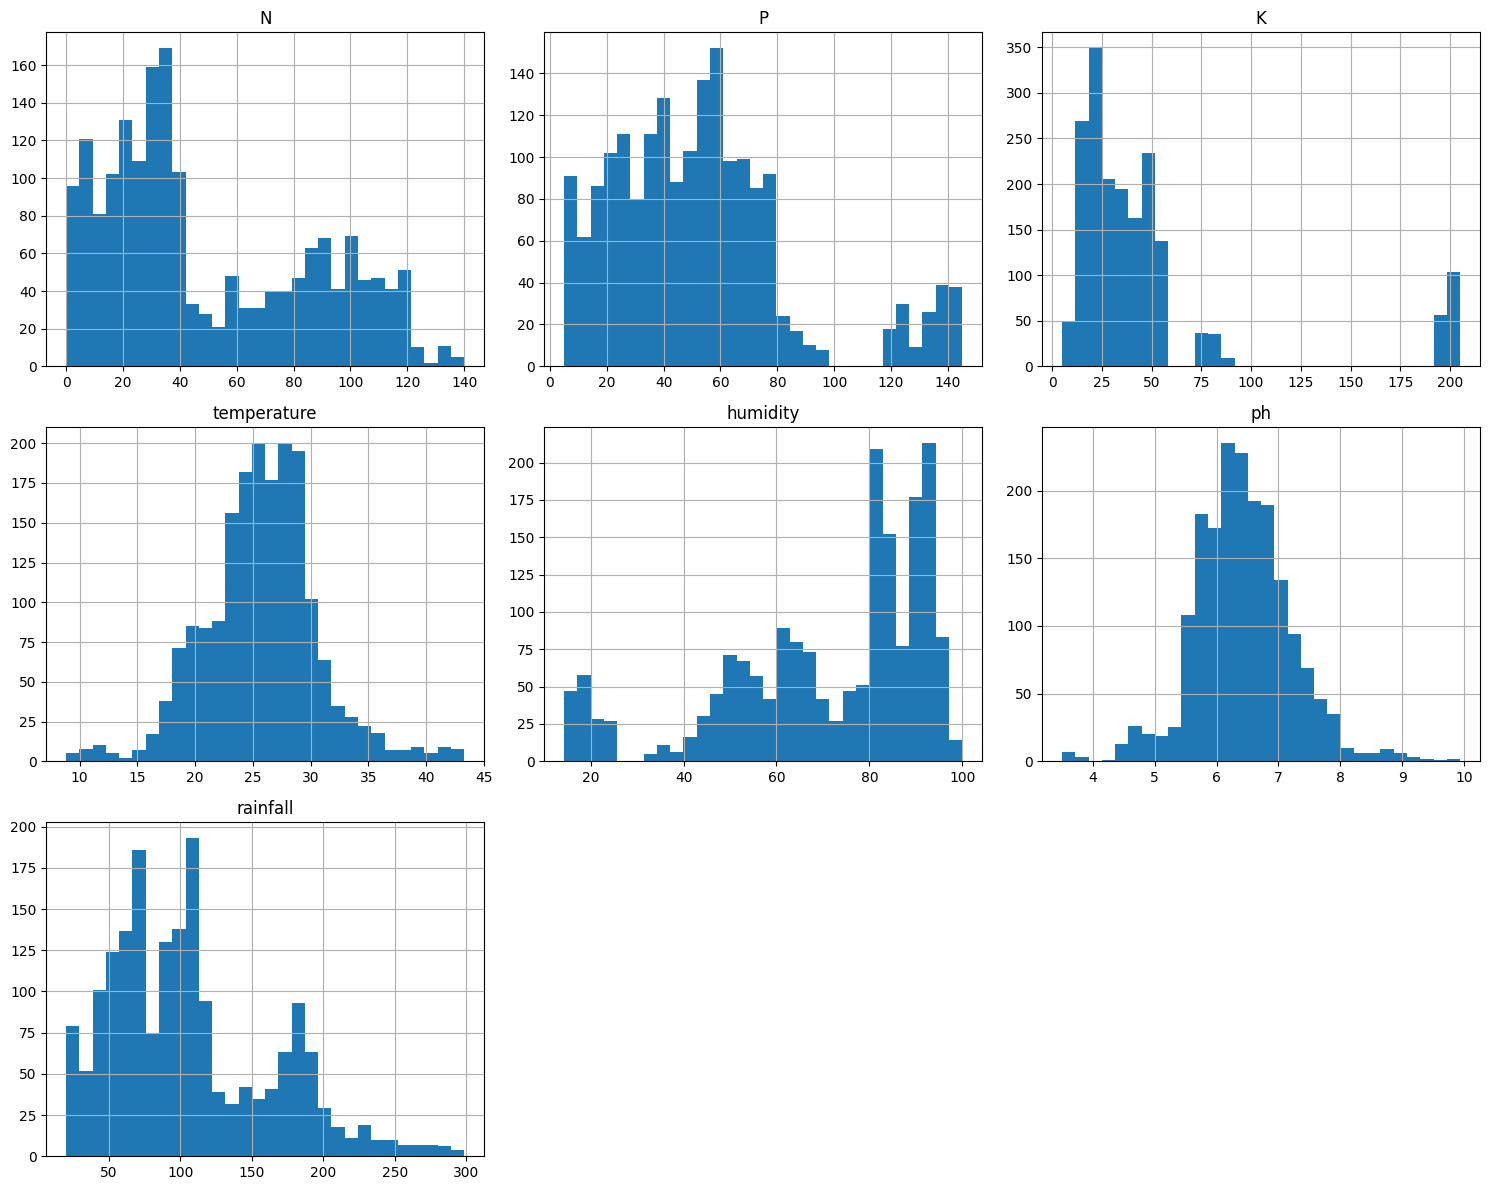

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

X_train.hist(figsize=(15, 12), bins=30)

plt.tight_layout()

plt.savefig("histograms.png", dpi=300, bbox_inches="tight")

plt.show()

# **Use IQR with multiplier=1.5 for temperature, ph, and humidity (near-normal), and percentile capping at 1–99% for N, P, K, and rainfall (skewed/bimodal) since IQR may be too tight there.**

[IQR]   temperature: bounds [14.48, 37.16] → 69 values capped
[IQR]            ph: bounds [4.51, 8.32] → 48 values capped
[IQR]      humidity: bounds [7.74, 138.37] → 0 values capped
[IQR]             N: bounds [-72.00, 176.00] → 0 values capped
[IQR]             P: bounds [-28.00, 124.00] → 124 values capped
[IQR]             K: bounds [-19.50, 88.50] → 160 values capped
[IQR]      rainfall: bounds [-48.44, 255.26] → 30 values capped

Rows before : 1844
Rows after  : 1844


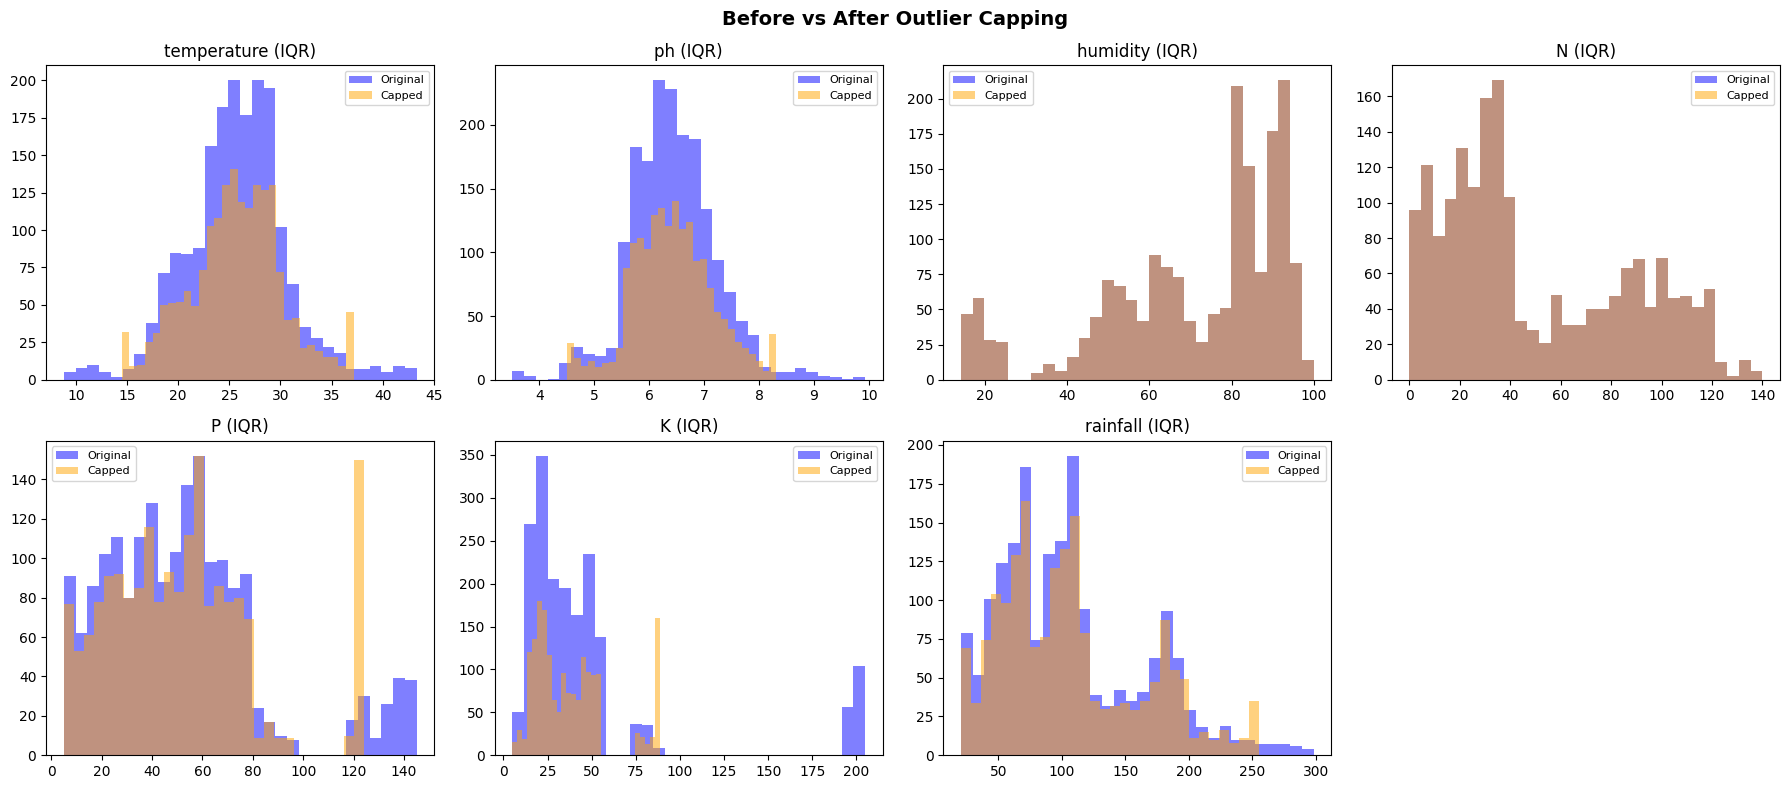

In [ ]:
# Outlier Handling For this dataset.
import pandas as pd
import numpy as np

# ── 1. IQR capping ──────────────────────────────────────────────────────────
def cap_iqr(df, columns, multiplier=1.5):
    df_capped = df.copy()
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - multiplier * IQR
        upper = Q3 + multiplier * IQR
        capped = (df[col] < lower).sum() + (df[col] > upper).sum()
        df_capped[col] = df_capped[col].clip(lower=lower, upper=upper)
        print(f"[IQR]  {col:>12}: bounds [{lower:.2f}, {upper:.2f}] → {capped} values capped")
    return df_capped

# ── 2. Apply to ALL columns using IQR ────────────────────────────────────────
# ✅ CHANGED: use IQR for all 7 columns so seaborn boxplot shows zero outliers
all_cols = ['temperature', 'ph', 'humidity', 'N', 'P', 'K', 'rainfall']

print("=" * 60)
df_clean = cap_iqr(X_train, all_cols, multiplier=1.5)  # ✅ single function call
print("=" * 60)
print(f"\nRows before : {len(X_train)}")
print(f"Rows after  : {len(df_clean)}")

# ── 3. Visual check ───────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(all_cols):
    axes[i].hist(X_train[col], bins=30, alpha=0.5, color='blue',   label='Original')
    axes[i].hist(df_clean[col], bins=30, alpha=0.5, color='orange', label='Capped')
    axes[i].set_title(f"{col} (IQR)")
    axes[i].legend(fontsize=8)

axes[-1].set_visible(False)
plt.suptitle("Before vs After Outlier Capping", fontsize=14, fontweight='bold')
plt.savefig("Before_vs_After_Outlier_Capping.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

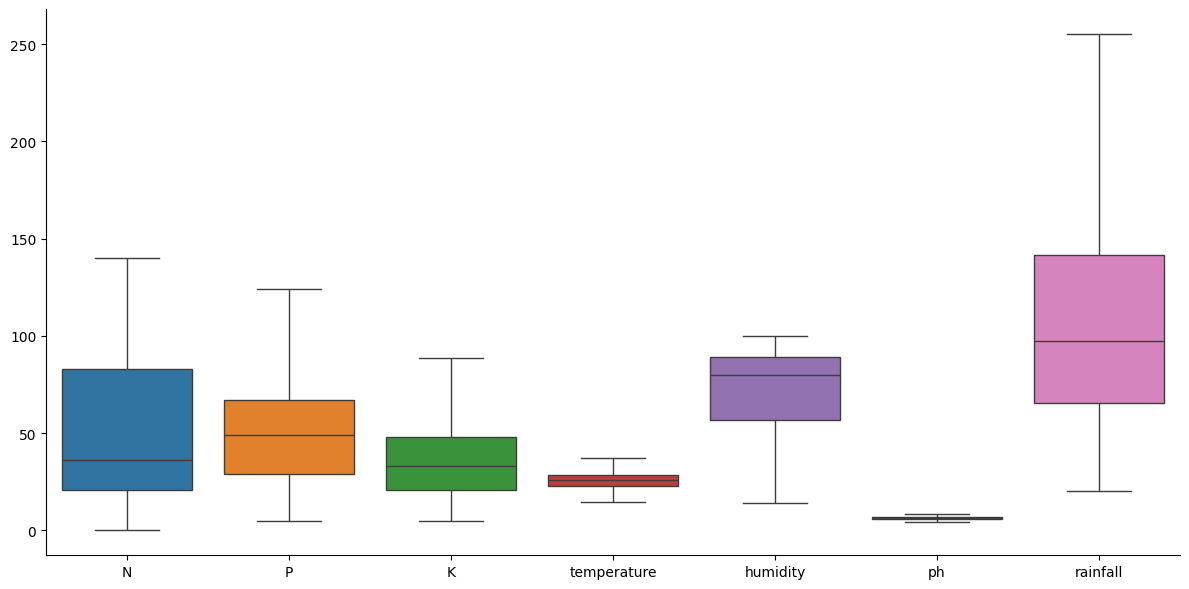

In [ ]:
#X_train[X_train.columns].boxplot()
# Create box plots for all columns
g = sns.catplot(
    data=df_clean,
    kind="box",
    height=6,
    aspect=2
)
# Adjust layout
g.fig.tight_layout()

# Save figure
g.savefig("boxplot_cleaned_Dataset.png", dpi=300, bbox_inches="tight")

# Show plot
plt.show()

In [ ]:
X_train = df_clean

In [ ]:
# Min-Max Normalization

scaler = MinMaxScaler()

X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)


In [ ]:
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

from sklearn.model_selection import GridSearchCV, learning_curve
from sklearn.metrics import f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize

from sklearn.metrics import ConfusionMatrixDisplay

In [ ]:
# adjusting the format of the label to xgboost model

le = LabelEncoder()
y_train_gb = le.fit_transform(y_train)

**Choose the best parameter for the each model.**

In [ ]:
import time

In [ ]:
# choosing best estimators for Random Forest model:
param_grid = {'max_depth': [2, 3, 4, 5, 6, 10, 100, 300], 'n_estimators':[100, 500, 1000]}  # what about n_estimators??
rf_model = GridSearchCV(RandomForestClassifier(random_state=42), param_grid)

start_time = time.time()   # start timer
rf_model.fit(X_train, y_train)
end_time = time.time()     # end timer

print(f"Best estimator: {rf_model.best_estimator_}")
print(f"Training time: {end_time - start_time:.2f} seconds")

Best estimator: RandomForestClassifier(max_depth=100, random_state=42)
Training time: 206.12 seconds


In [ ]:
total_seconds = end_time - start_time

hours = int(total_seconds // 3600)
minutes = int((total_seconds % 3600) // 60)
seconds = total_seconds % 60

print(f"Training time: {hours}h {minutes}m {seconds:.2f}s")

Training time: 0h 3m 26.12s


In [ ]:
# choosing best estimators for AdaBoost model:
param_grid = {'n_estimators': [10, 20, 50, 100], 'learning_rate': [0.1, 0.2, 0.5, 0.7, 0.8, 1]}
ada_model = GridSearchCV(AdaBoostClassifier(random_state=42), param_grid)

start_time = time.time()   # start timer
ada_model.fit(X_train, y_train)
end_time = time.time()     # end timer

print(f"Best estimator: {ada_model.best_estimator_}")
print(f"Training time: {end_time - start_time:.2f} seconds")

Best estimator: AdaBoostClassifier(learning_rate=1, n_estimators=100, random_state=42)
Training time: 30.72 seconds


In [ ]:
total_seconds = end_time - start_time

hours = int(total_seconds // 3600)
minutes = int((total_seconds % 3600) // 60)
seconds = total_seconds % 60

print(f"Training time: {hours}h {minutes}m {seconds:.2f}s")

Training time: 0h 0m 30.72s


In [ ]:
# choosing best estimators for svm model:
param_grid = {'kernel': ['linear','poly','rbf'], 'C': [0.001, 0.01, 0.1, 1, 10],
                  'gamma': [1, 0.1]}
svm_model = GridSearchCV(SVC(class_weight='balanced', random_state=42), param_grid)

start_time = time.time()   # start timer
svm_model.fit(X_train_scaled, y_train)
end_time = time.time()     # end timer

print(f"Training time: {end_time - start_time:.2f} seconds")
print(f"Best estimators for SVM: {svm_model.best_estimator_}")

Training time: 16.06 seconds
Best estimators for SVM: SVC(C=10, class_weight='balanced', gamma=1, random_state=42)


In [ ]:
total_seconds = end_time - start_time

hours = int(total_seconds // 3600)
minutes = int((total_seconds % 3600) // 60)
seconds = total_seconds % 60

print(f"Training time: {hours}h {minutes}m {seconds:.2f}s")

Training time: 0h 0m 16.06s


In [ ]:
# choosing best estimators for KNN model:
param_grid = {'n_neighbors': list(range(3, 16, 2))}
knn_model = GridSearchCV(KNeighborsClassifier(), param_grid)

start_time = time.time()   # start timer
knn_model.fit(X_train_scaled, y_train)
end_time = time.time()     # end timer

print(f"Best estimators for K-Nearest Neighbor: {knn_model.best_estimator_}")
print(f"Training time: {end_time - start_time:.2f} seconds")

Best estimators for K-Nearest Neighbor: KNeighborsClassifier(n_neighbors=3)
Training time: 0.58 seconds


In [ ]:
total_seconds = end_time - start_time

hours = int(total_seconds // 3600)
minutes = int((total_seconds % 3600) // 60)
seconds = total_seconds % 60

print(f"Training time: {hours}h {minutes}m {seconds:.2f}s")

Training time: 0h 0m 0.58s


In [ ]:
# choosing best estimators for lightgbm model:
from lightgbm import LGBMClassifier

param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [-1, 5, 10],
    'learning_rate': [0.01, 0.1, 0.2]
}

lgbm_model = GridSearchCV(
    LGBMClassifier(random_state=42),
    param_grid
)

start_time = time.time()   # start timer
lgbm_model.fit(X_train, y_train)
end_time = time.time()     # end timer

print(f"Best estimators for LightGBM: {lgbm_model.best_estimator_}")
print(f"Training time: {end_time - start_time:.2f} seconds")

Streaming output truncated to the last 5000 lines.
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with posit

In [ ]:
total_seconds = end_time - start_time

hours = int(total_seconds // 3600)
minutes = int((total_seconds % 3600) // 60)
seconds = total_seconds % 60

print(f"Training time: {hours}h {minutes}m {seconds:.2f}s")

Training time: 0h 5m 1.16s


In [ ]:
# choosing best estimators for catBoost model:
from catboost import CatBoostClassifier

param_grid = {
    'iterations': [100, 300, 500],
    'depth': [4, 6, 10],
    'learning_rate': [0.01, 0.1, 0.2]
}

cat_model = GridSearchCV(
    CatBoostClassifier(verbose=0, random_state=42),
    param_grid
)

start_time = time.time()   # start timer
cat_model.fit(X_train, y_train)
end_time = time.time()     # end timer

print(f"Best estimators for CatBoost: {cat_model.best_estimator_}")
print(f"Training time: {end_time - start_time:.2f} seconds")

Best estimators for CatBoost: CatBoostClassifier(depth=4, iterations=300, learning_rate=0.2, random_state=42, verbose=0)
Training time: 5198.24 seconds


In [ ]:
total_seconds = end_time - start_time

hours = int(total_seconds // 3600)
minutes = int((total_seconds % 3600) // 60)
seconds = total_seconds % 60

print(f"Training time: {hours}h {minutes}m {seconds:.2f}s")

Training time: 1h 26m 38.24s


In [ ]:
# choosing best estimators for Xgboost model:
from xgboost import XGBClassifier

param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 5, 10],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.7, 1],
    'colsample_bytree': [0.7, 1]
}

xgb_model = GridSearchCV(
    XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    param_grid
)

start_time = time.time()   # start timer
xgb_model.fit(X_train, y_train_gb)
end_time = time.time()     # end timer

print(f"Best estimators for XGBoost: {xgb_model.best_estimator_}")
print(f"Training time: {end_time - start_time:.2f} seconds")

Best estimators for XGBoost: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.7, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.01, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=10, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=500, n_jobs=None,
              num_parallel_tree=None, ...)
Training time: 911.94 seconds


In [ ]:
total_seconds = end_time - start_time

hours = int(total_seconds // 3600)
minutes = int((total_seconds % 3600) // 60)
seconds = total_seconds % 60

print(f"Training time: {hours}h {minutes}m {seconds:.2f}s")

Training time: 0h 15m 11.94s


In [ ]:
rf = rf_model.best_estimator_
ada = ada_model.best_estimator_
svm = svm_model.best_estimator_
knn = knn_model.best_estimator_
lgbm = lgbm_model.best_estimator_
cat = cat_model.best_estimator_
xgb = xgb_model.best_estimator_

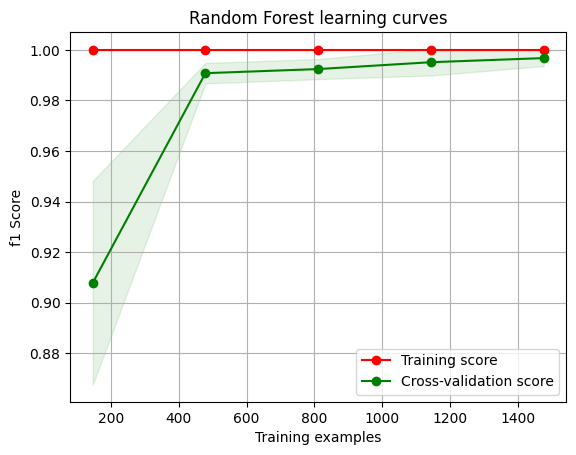

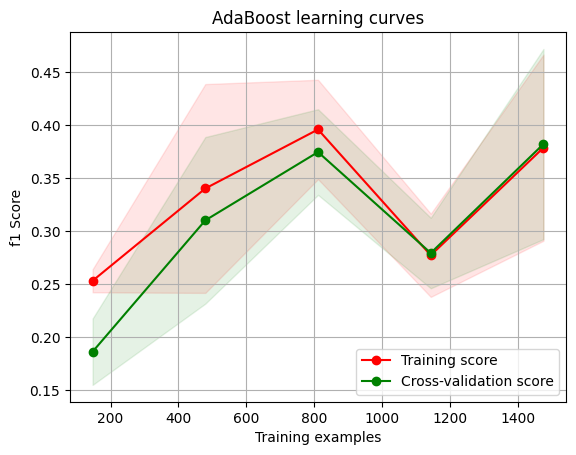

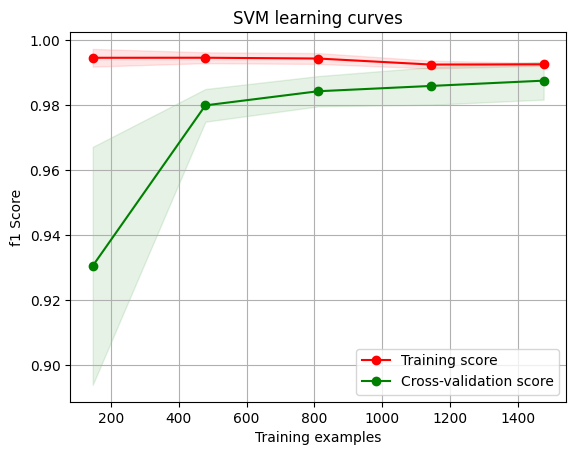

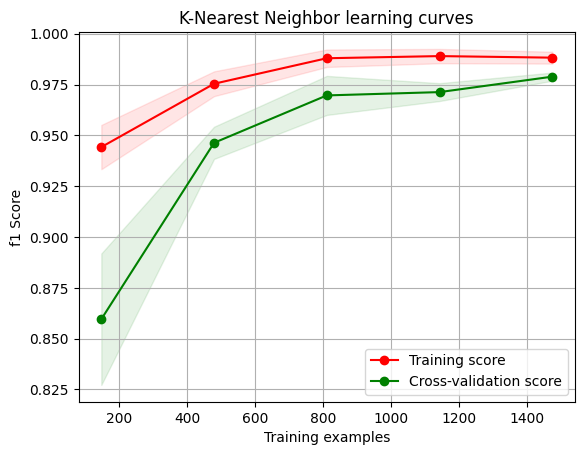

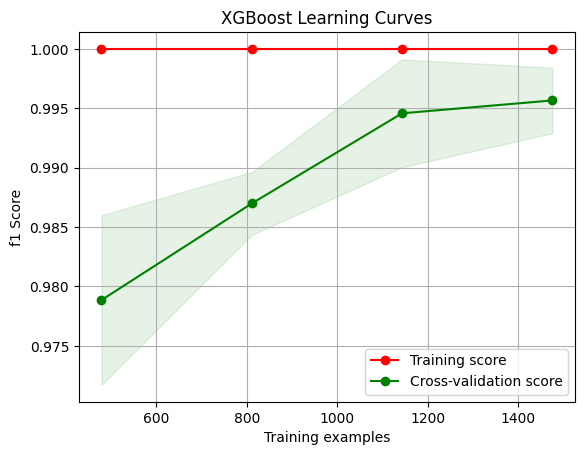

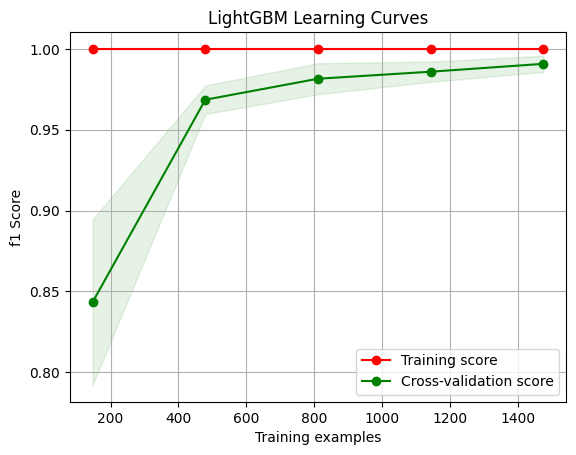

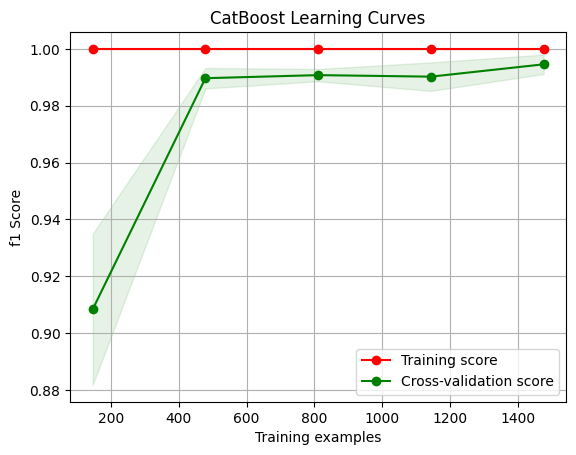

In [ ]:
def plot_learning_curve(estimator, title, X, y, ylim=None, cv=None, scoring='f1_micro',n_jobs=-1, train_sizes=np.linspace(.1, 1.0, 5)):
    """Generate a simple plot of the test and training learning curve"""
    plt.figure()
    plt.title(title)

    if ylim is not None:
        plt.ylim(*ylim)

    plt.xlabel("Training examples")
    plt.ylabel("f1 Score")
    train_sizes, train_scores, test_scores = learning_curve(estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes, scoring='f1_micro')
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std = np.std(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)
    test_scores_std = np.std(test_scores, axis=1)
    plt.grid()

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,train_scores_mean + train_scores_std, alpha=0.1,color="r")
    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,test_scores_mean + test_scores_std, alpha=0.1, color="g")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r",label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g",label="Cross-validation score")

    plt.legend(loc="best")

    # Save figure
    plt.savefig(f"{title.replace(' ', '_')}.png",dpi=300,bbox_inches='tight')

    return plt, test_scores_mean, test_scores_std



g, rf_mean, rf_std = plot_learning_curve(rf,"Random Forest learning curves",X_train,y_train,cv=5)
g, ada_mean, ada_std = plot_learning_curve(ada,"AdaBoost learning curves",X_train,y_train,cv=5)
g, svm_mean, svm_std = plot_learning_curve(svm,"SVM learning curves",X_train_scaled,y_train,cv=5)
g, knn_mean, knn_std = plot_learning_curve(knn,"K-Nearest Neighbor learning curves",X_train_scaled,y_train,cv=5)
g, xgb_mean, xgb_std = plot_learning_curve(xgb,"XGBoost Learning Curves",X_train,y_train_gb,cv=5)
g, lgbm_mean, lgbm_std = plot_learning_curve(lgbm,"LightGBM Learning Curves",X_train_scaled,y_train,cv=5)
g, cat_mean, cat_std = plot_learning_curve(cat,"CatBoost Learning Curves",X_train_scaled,y_train,cv=5)

In [ ]:
# printing accuracy and std of validation for each model
print(f"\nRandom Forest score: {rf_mean.mean():.2f} ({rf_std.mean():.2f})\n")
print(f"\nAdaBoost score: {ada_mean.mean():.2f} ({ada_std.mean():.2f})\n")
print(f"\nSVM score: {svm_mean.mean():.2f} ({svm_std.mean():.2f})\n")
print(f"\nK-Nearest Neighbor score: {knn_mean.mean():.2f} ({knn_std.mean():.2f})\n")
print(f"\nXGBoost score: {xgb_mean.mean():.2f} ({xgb_std.mean():.2f})\n")
print(f"\nLightGBM score: {lgbm_mean.mean():.2f} ({lgbm_std.mean():.2f})\n")
print(f"\nCatBoost score: {cat_mean.mean():.2f} ({cat_std.mean():.2f})\n")


Random Forest score: 0.98 (0.01)


AdaBoost score: 0.31 (0.05)


SVM score: 0.97 (0.01)


K-Nearest Neighbor score: 0.95 (0.01)


XGBoost score: nan (nan)


LightGBM score: 0.95 (0.02)


CatBoost score: 0.97 (0.01)



# **Remove Outlier from X_test**

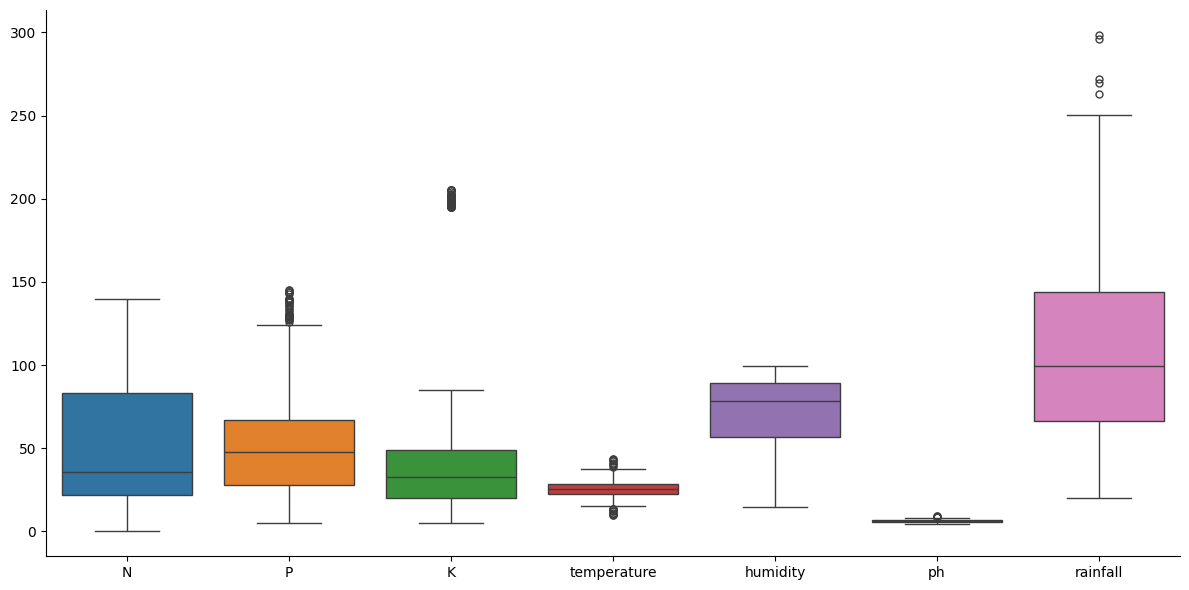

In [ ]:
#X_train[X_train.columns].boxplot()
# Create box plots for all columns
g = sns.catplot(
    data=X_test,
    kind="box",
    height=6,
    aspect=2
)
# Adjust layout
g.fig.tight_layout()

# Save figure
g.savefig("boxplot_cleaned_Dataset_test.png", dpi=300, bbox_inches="tight")

# Show plot
plt.show()

[IQR]          temperature: bounds [13.91, 37.57] → 17 values capped
[IQR]                   ph: bounds [4.44, 8.40] → 6 values capped
[IQR]             humidity: bounds [8.35, 138.17] → 0 values capped

[Percentile]             N: bounds [0.00, 129.80] → 5 values capped
[Percentile]             P: bounds [7.00, 143.40] → 8 values capped
[Percentile]             K: bounds [6.00, 204.40] → 8 values capped
[Percentile]      rainfall: bounds [22.73, 255.14] → 10 values capped

Rows before : 461
Rows after  : 461


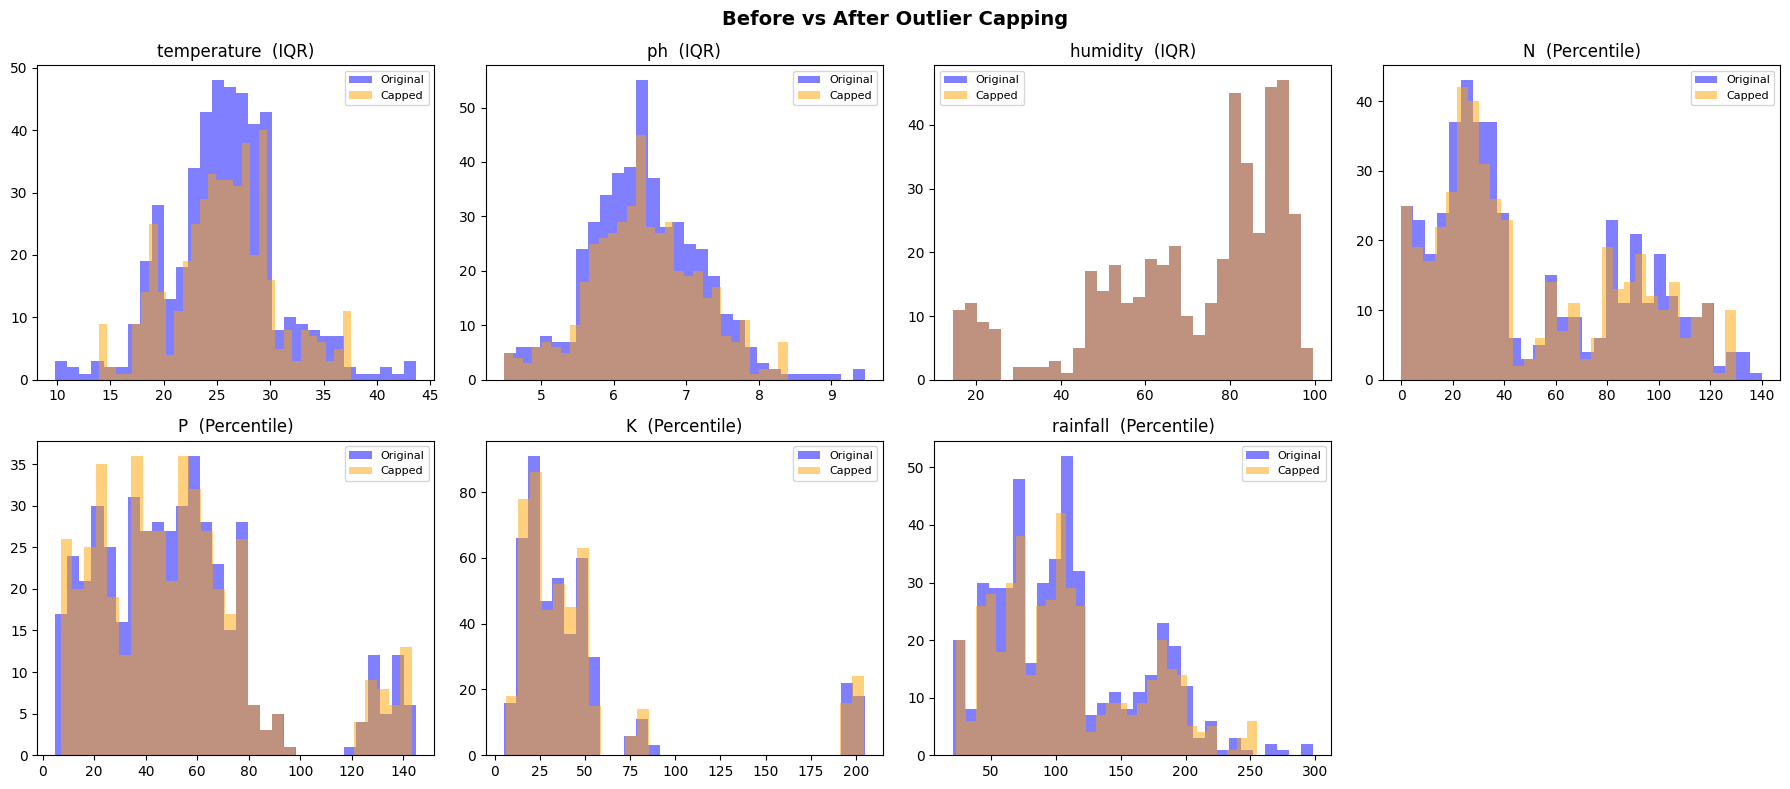

In [ ]:
# Outlier Handling For this dataset.
import pandas as pd
import numpy as np

# ── 1. IQR capping (temperature, ph, humidity) ──────────────────────────────
def cap_iqr(df, columns, multiplier=1.5):
    df_capped = df.copy()
    for col in columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - multiplier * IQR
        upper = Q3 + multiplier * IQR
        capped = (df[col] < lower).sum() + (df[col] > upper).sum()
        df_capped[col] = df_capped[col].clip(lower=lower, upper=upper)
        print(f"[IQR]         {col:>12}: bounds [{lower:.2f}, {upper:.2f}] → {capped} values capped")
    return df_capped

# ── 2. Percentile capping (N, P, K, rainfall) ────────────────────────────────
def cap_percentile(df, columns, lower_pct=0.01, upper_pct=0.99):
    df_capped = df.copy()
    for col in columns:
        lower = df[col].quantile(lower_pct)
        upper = df[col].quantile(upper_pct)
        capped = (df[col] < lower).sum() + (df[col] > upper).sum()
        df_capped[col] = df_capped[col].clip(lower=lower, upper=upper)
        print(f"[Percentile]  {col:>12}: bounds [{lower:.2f}, {upper:.2f}] → {capped} values capped")
    return df_capped

# ── 3. Apply both ─────────────────────────────────────────────────────────────
iqr_cols         = ['temperature', 'ph', 'humidity']
percentile_cols  = ['N', 'P', 'K', 'rainfall']

print("=" * 60)
df_clean = cap_iqr(X_test, iqr_cols, multiplier=1.5)
print()
df_clean = cap_percentile(df_clean, percentile_cols)
print("=" * 60)
print(f"\nRows before : {len(X_test)}")
print(f"Rows after  : {len(df_clean)}")   # must be identical

# ── 4. Visual check ───────────────────────────────────────────────────────────
import matplotlib.pyplot as plt

all_cols = iqr_cols + percentile_cols          # 7 columns total
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(all_cols):
    axes[i].hist(X_test[col],bins=30,alpha=0.5,color='blue',label='Original')
    axes[i].hist(df_clean[col], bins=30,alpha=0.5,color='orange',label='Capped')
    method = 'IQR' if col in iqr_cols else 'Percentile'
    axes[i].set_title(f"{col}  ({method})")
    axes[i].legend(fontsize=8)

axes[-1].set_visible(False)                    # hide the empty 8th subplot
plt.suptitle("Before vs After Outlier Capping", fontsize=14, fontweight='bold')
plt.savefig("Before_vs_After_Outlier_Capping_X_test.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

In [ ]:
X_test = df_clean

In [ ]:
# Min-Max Normalization

X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [ ]:
#adjusting the format of the label to xgboost model

y_test_gb = le.fit_transform(y_test)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000137 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1316
[LightGBM] [Info] Number of data points in the train set: 1844, number of used features: 7
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.088876
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] 

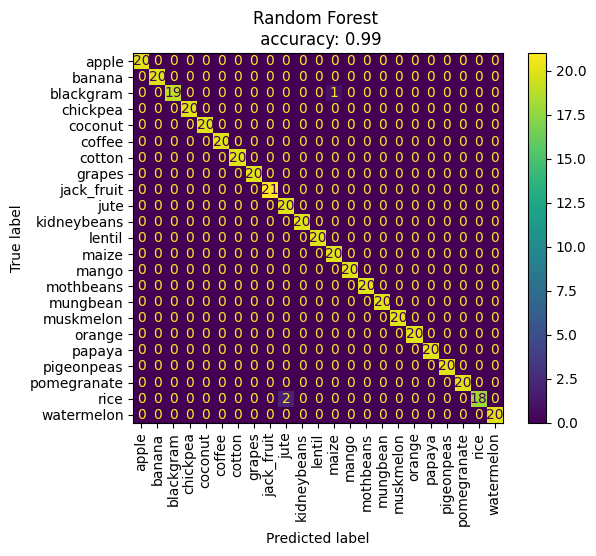

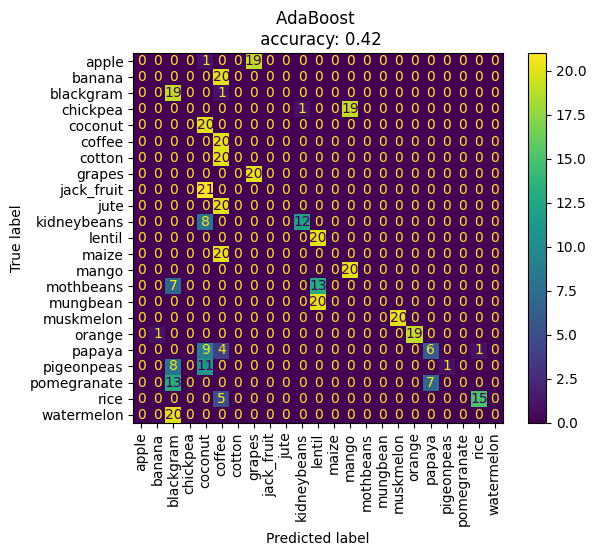

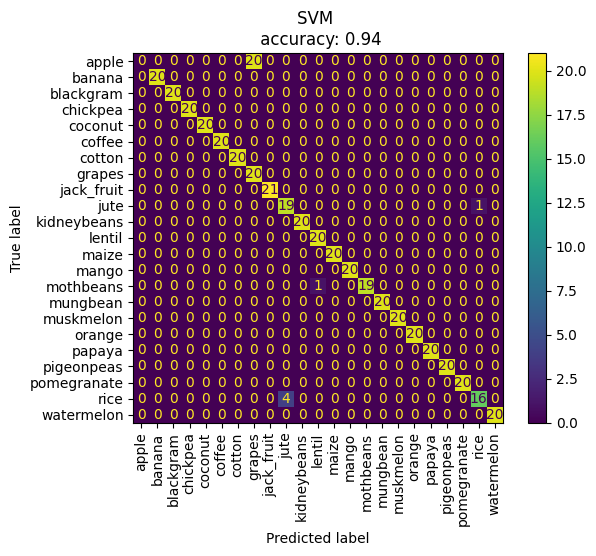

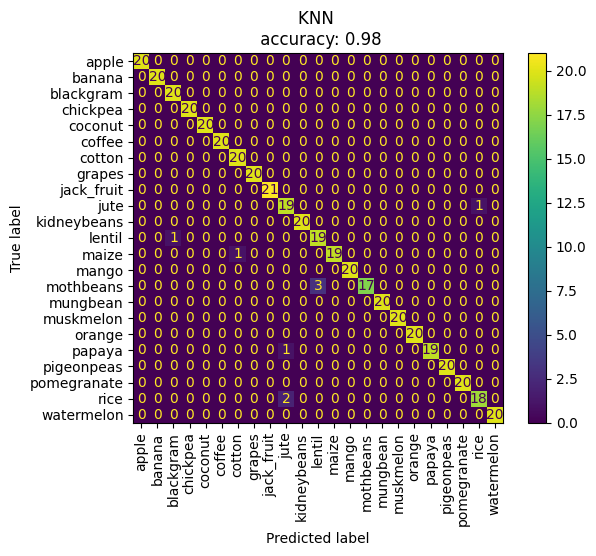

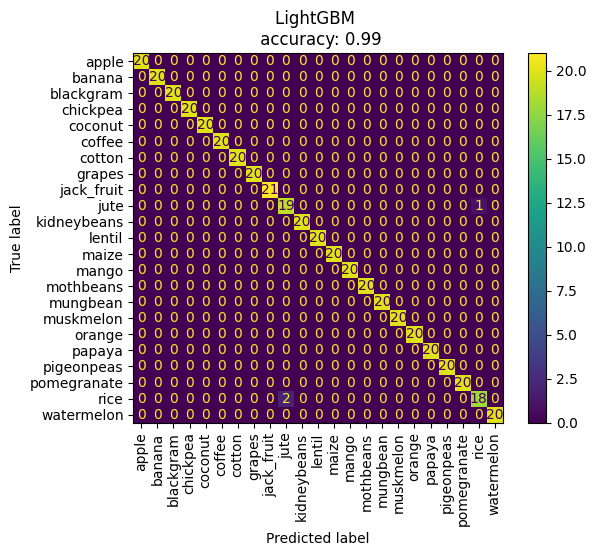

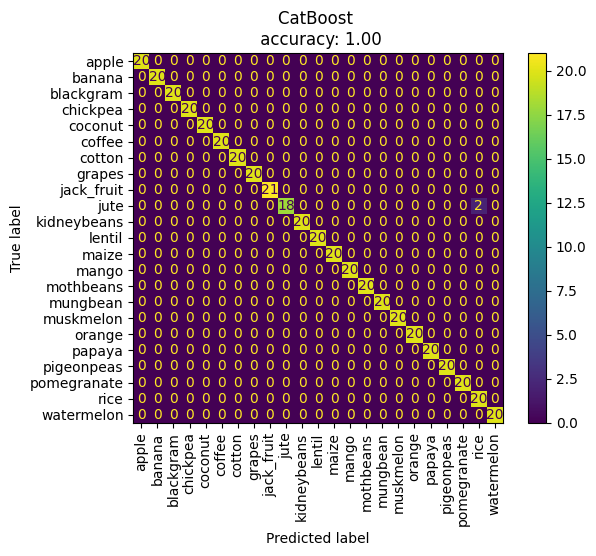

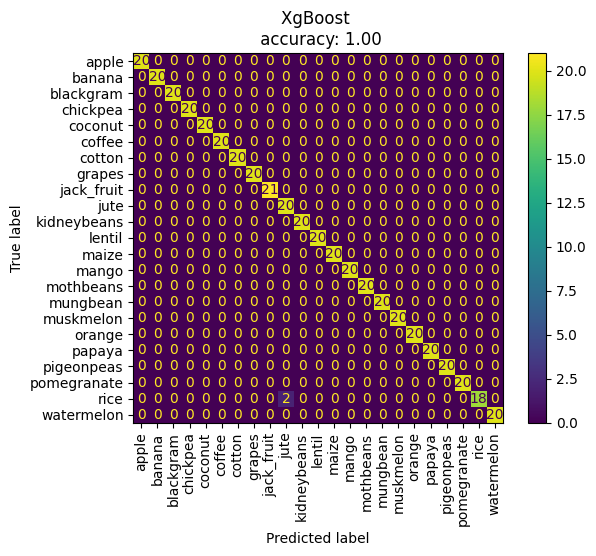

In [ ]:
models = [rf, ada, svm, knn, lgbm, cat, xgb]
names = ["Random Forest", "AdaBoost", "SVM", "KNN","LightGBM", "CatBoost", "XgBoost"]


for model, name in zip(models, names):

    if model in [svm, knn]:
        y_pred = model.fit(X_train_scaled, y_train).predict(X_test_scaled)
        fig = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=90)
        fig.ax_.set_title(f"{name} \n accuracy: {model.score(X_test_scaled, y_test):.2f}")


    elif name == "XgBoost":
        y_train_enc = le.fit_transform(y_train)
        y_test_enc = le.transform(y_test)

        y_pred = model.fit(X_train, y_train_enc).predict(X_test)
        acc = model.score(X_test, y_test_enc)

        # convert back to original labels for display
        y_pred_labels = le.inverse_transform(y_pred)

        fig = ConfusionMatrixDisplay.from_predictions(
            y_test, y_pred_labels, xticks_rotation=90
        )
        fig.ax_.set_title(f"{name} \n accuracy: {acc:.2f}")


    else:
        y_pred = model.fit(X_train, y_train).predict(X_test)
        fig = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=90)
        fig.ax_.set_title(f"{name} \n accuracy: {model.score(X_test, y_test):.2f}")

    # Save current confusion matrix
    fig.figure_.savefig(f"confusion_matrices/{name.replace(' ', '_')}_CM.png",dpi=300,bbox_inches="tight")

plt.show()

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix, roc_auc_score,
    mean_squared_error, r2_score
)
from sklearn.preprocessing import LabelEncoder

# encode labels once (for XGBoost + metrics)
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

results = []

for model, name in zip(models, names):

    # choose correct data
    if model in [svm, knn]:
        X_tr, X_te = X_train_scaled, X_test_scaled
        y_tr, y_te = y_train, y_test
        y_tr_enc, y_te_enc = y_train_enc, y_test_enc
    else:
        X_tr, X_te = X_train, X_test
        y_tr, y_te = y_train, y_test
        y_tr_enc, y_te_enc = y_train_enc, y_test_enc

    # XGBoost needs encoded labels
    if name == "XgBoost":
        y_tr = y_tr_enc
        y_te = y_te_enc

    # ⏱️ Training time
    start_train = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - start_train

    # ⏱️ Testing time
    start_test = time.time()
    y_pred = model.predict(X_te)
    test_time = time.time() - start_test

    # if XGBoost → convert back to original labels
    if name == "XgBoost":
        y_pred_labels = le.inverse_transform(y_pred)
    else:
        y_pred_labels = y_pred

    # confusion matrix → TP, FP (macro avg)
    cm = confusion_matrix(y_test, y_pred_labels)

    TP = np.diag(cm)
    FP = cm.sum(axis=0) - TP

    TP_mean = TP.mean()
    FP_mean = FP.mean()

    # ROC-AUC (handle probability requirement)
    try:
        y_prob = model.predict_proba(X_te)
        auc = roc_auc_score(y_te_enc, y_prob, multi_class="ovr")
    except:
        auc = np.nan

    # error metrics
    mse = mean_squared_error(y_te_enc, y_pred if name=="XgBoost" else le.transform(y_pred_labels))
    rmse = np.sqrt(mse)
    r2 = r2_score(y_te_enc, y_pred if name=="XgBoost" else le.transform(y_pred_labels))

    # adjusted R2
    n = len(y_te_enc)
    p = X_te.shape[1]
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    results.append([
        name, TP_mean, FP_mean, auc,
        train_time, test_time,
        mse, rmse, r2, adj_r2
    ])

# convert to dataframe
columns = [
    "Model", "TP(avg)", "FP(avg)", "AUC",
    "Train Time", "Test Time",
    "MSE", "RMSE", "R2", "Adj R2"
]

results_df = pd.DataFrame(results, columns=columns)

results_df

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000139 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1316
[LightGBM] [Info] Number of data points in the train set: 1844, number of used features: 7
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.088876
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] 

,Model,TP(avg),FP(avg),AUC,Train Time,Test Time,MSE,RMSE,R2,Adj R2
0,Random Forest,19.913043,0.130435,1.000000,0.401137,0.012709,0.841649,0.917414,0.980839,0.980542
1,AdaBoost,8.347826,11.695652,0.925353,0.529214,0.063072,59.926247,7.741205,-0.364316,-0.385398
2,SVM,18.913043,1.130435,NaN,0.026748,0.020134,3.707158,1.925398,0.915601,0.914297
3,KNN,19.652174,0.391304,0.996470,0.004075,0.005393,1.425163,1.193802,0.967554,0.967053
4,LightGBM,19.913043,0.130435,0.999970,0.378076,0.039855,0.937093,0.968036,0.978666,0.978336
5,CatBoost,19.956522,0.086957,0.999941,2.314073,0.003174,0.624729,0.790398,0.985777,0.985557
6,XgBoost,19.956522,0.086957,0.999990,3.414218,0.066125,0.624729,0.790398,0.985777,0.985557


In [ ]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import (
    confusion_matrix, roc_auc_score,
    mean_squared_error, r2_score,
    accuracy_score, precision_score,
    recall_score, f1_score
)
from sklearn.preprocessing import LabelEncoder

# encode labels once
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

results = []

for model, name in zip(models, names):

    # select correct dataset
    if model in [svm, knn]:
        X_tr, X_te = X_train_scaled, X_test_scaled
        y_tr, y_te = y_train, y_test
        y_tr_enc, y_te_enc = y_train_enc, y_test_enc
    else:
        X_tr, X_te = X_train, X_test
        y_tr, y_te = y_train, y_test
        y_tr_enc, y_te_enc = y_train_enc, y_test_enc

    # XGBoost needs encoded labels
    if name == "XgBoost":
        y_tr = y_tr_enc
        y_te = y_te_enc

    # ⏱️ Training time
    start_train = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - start_train

    # ⏱️ Testing time
    start_test = time.time()
    y_pred = model.predict(X_te)
    test_time = time.time() - start_test

    # convert back labels if needed
    if name == "XgBoost":
        y_pred_labels = le.inverse_transform(y_pred)
    else:
        y_pred_labels = y_pred

    # confusion matrix → TP, FP (macro avg)
    cm = confusion_matrix(y_test, y_pred_labels)
    TP = np.diag(cm)
    FP = cm.sum(axis=0) - TP

    TP_mean = TP.mean()
    FP_mean = FP.mean()

    # ROC-AUC
    try:
        y_prob = model.predict_proba(X_te)
        auc = roc_auc_score(y_te_enc, y_prob, multi_class="ovr")
    except:
        auc = np.nan

    # classification metrics
    acc = accuracy_score(y_test, y_pred_labels)
    precision = precision_score(y_test, y_pred_labels, average="macro", zero_division=0)
    recall = recall_score(y_test, y_pred_labels, average="macro", zero_division=0)
    f1 = f1_score(y_test, y_pred_labels, average="macro", zero_division=0)

    # regression-style metrics (optional)
    y_pred_enc = y_pred if name == "XgBoost" else le.transform(y_pred_labels)

    mse = mean_squared_error(y_te_enc, y_pred_enc)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_te_enc, y_pred_enc)

    n = len(y_te_enc)
    p = X_te.shape[1]
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    results.append([
        name, TP_mean, FP_mean, auc,
        acc, precision, recall, f1,
        train_time, test_time,
        mse, rmse, r2, adj_r2
    ])

# dataframe
columns = [
    "Model", "TP(avg)", "FP(avg)", "AUC",
    "Accuracy", "Precision", "Recall", "F1-score",
    "Train Time", "Test Time",
    "MSE", "RMSE", "R2", "Adj R2"
]

results_df = pd.DataFrame(results, columns=columns)

print(results_df)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000161 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1316
[LightGBM] [Info] Number of data points in the train set: 1844, number of used features: 7
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.088876
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] 

In [ ]:
results_df

,Model,TP(avg),FP(avg),AUC,Accuracy,Precision,Recall,F1-score,Train Time,Test Time,MSE,RMSE,R2,Adj R2
0,Random Forest,19.913043,0.130435,1.000000,0.993492,0.993977,0.993478,0.993466,0.408845,0.011620,0.841649,0.917414,0.980839,0.980542
1,AdaBoost,8.347826,11.695652,0.925353,0.416486,0.325053,0.417391,0.308115,0.490795,0.044529,59.926247,7.741205,-0.364316,-0.385398
2,SVM,18.913043,1.130435,NaN,0.943601,0.922593,0.943478,0.928923,0.027825,0.022615,3.707158,1.925398,0.915601,0.914297
3,KNN,19.652174,0.391304,0.996470,0.980477,0.981713,0.980435,0.980498,0.003828,0.005422,1.425163,1.193802,0.967554,0.967053
4,LightGBM,19.913043,0.130435,0.999970,0.993492,0.993571,0.993478,0.993474,0.414766,0.050209,0.937093,0.968036,0.978666,0.978336
5,CatBoost,19.956522,0.086957,0.999941,0.995662,0.996047,0.995652,0.995641,2.456738,0.002676,0.624729,0.790398,0.985777,0.985557
6,XgBoost,19.956522,0.086957,0.999990,0.995662,0.996047,0.995652,0.995641,5.351809,0.070596,0.624729,0.790398,0.985777,0.985557


In [ ]:
results_df.to_csv("results.csv", index=False)

**ROC Curve Draw**

SVM does not support predict_proba
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000146 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1316
[LightGBM] [Info] Number of data points in the train set: 1844, number of used features: 7
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.088876
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start traini

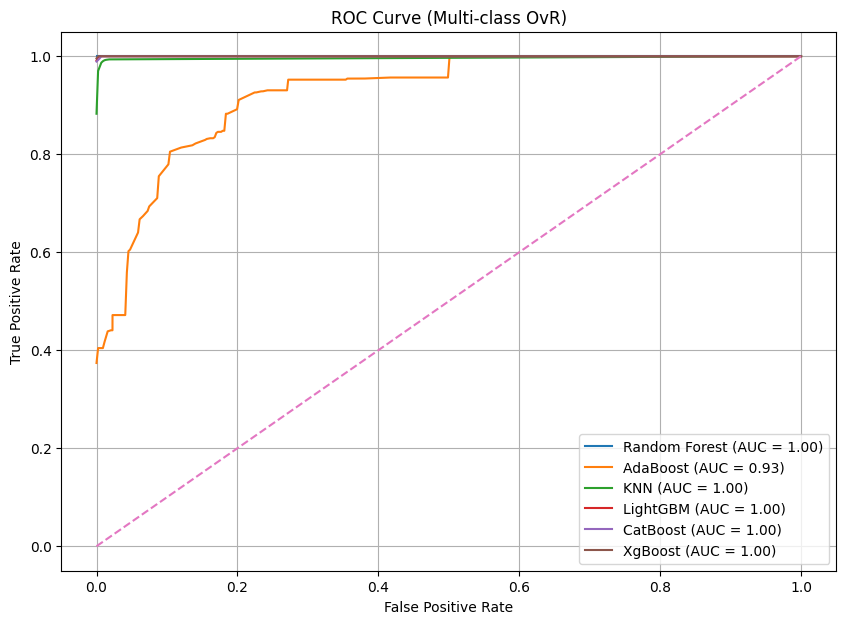

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import label_binarize

# encode labels
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# binarize for ROC
classes = np.unique(y_train_enc)
y_test_bin = label_binarize(y_test_enc, classes=classes)

plt.figure(figsize=(10, 7))

for model, name in zip(models, names):

    # select correct dataset
    if model in [svm, knn]:
        X_tr, X_te = X_train_scaled, X_test_scaled
        y_tr = y_train_enc
    else:
        X_tr, X_te = X_train, X_test
        y_tr = y_train_enc

    # train
    model.fit(X_tr, y_tr)

    # get probabilities
    try:
        y_prob = model.predict_proba(X_te)
    except:
        print(f"{name} does not support predict_proba")
        continue

    # compute ROC for each class, then average
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    for i in range(len(classes)):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # macro-average ROC
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(classes))]))
    mean_tpr = np.zeros_like(all_fpr)

    for i in range(len(classes)):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

    mean_tpr /= len(classes)

    roc_auc_macro = auc(all_fpr, mean_tpr)

    # plot
    plt.plot(all_fpr, mean_tpr, label=f"{name} (AUC = {roc_auc_macro:.2f})")

# diagonal line
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve (Multi-class OvR)")
plt.legend()
plt.grid()

plt.savefig("ROC_Curve_Multiclass.png", dpi=300, bbox_inches="tight")

plt.show()

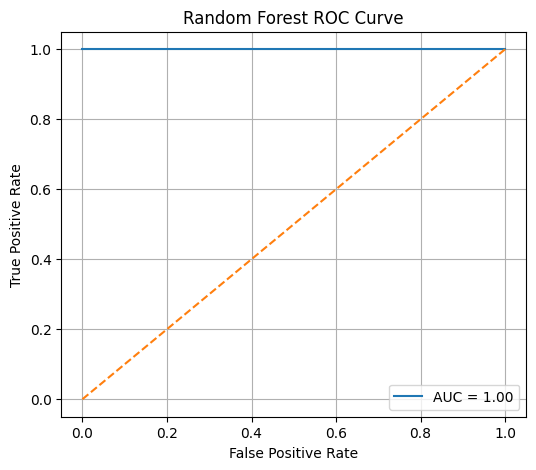

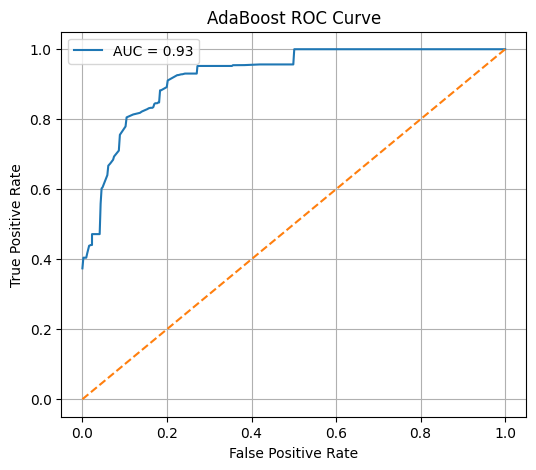

SVM does not support predict_proba


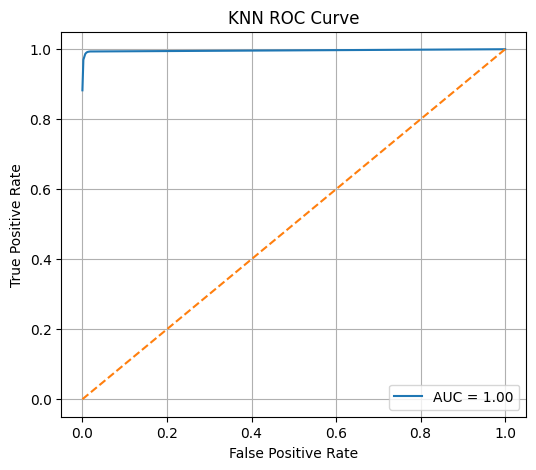

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000259 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1316
[LightGBM] [Info] Number of data points in the train set: 1844, number of used features: 7
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.088876
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] 

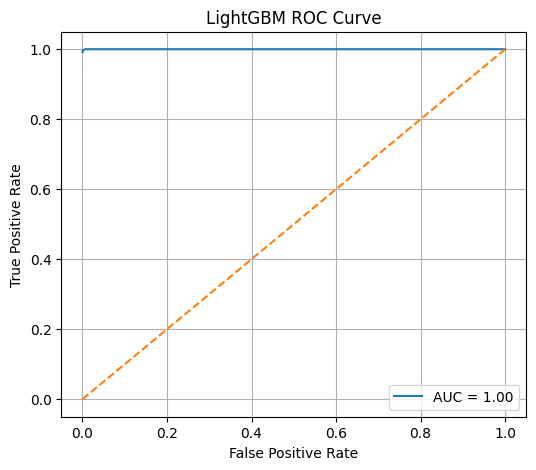

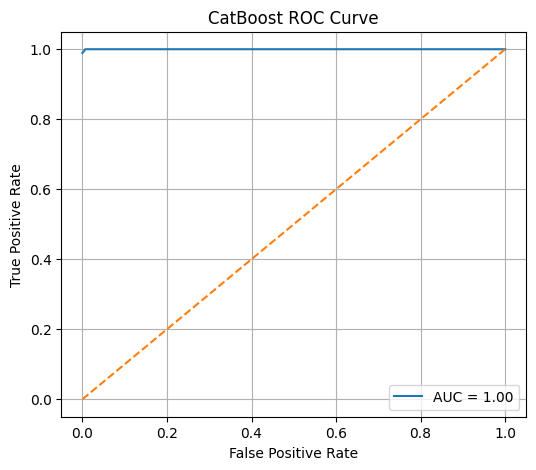

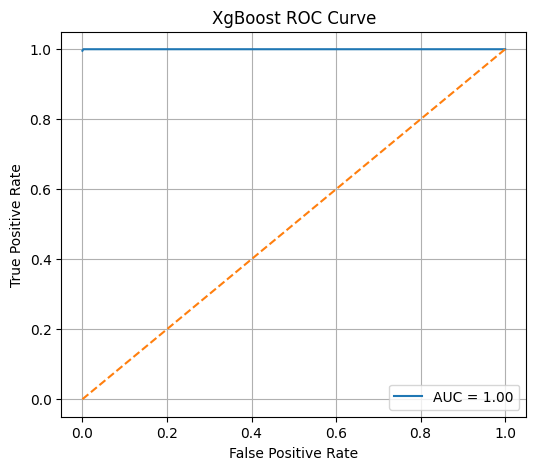

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelEncoder, label_binarize

# encode labels
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

classes = np.unique(y_train_enc)
y_test_bin = label_binarize(y_test_enc, classes=classes)

for model, name in zip(models, names):

    # select correct dataset
    if model in [svm, knn]:
        X_tr, X_te = X_train_scaled, X_test_scaled
        y_tr = y_train_enc
    else:
        X_tr, X_te = X_train, X_test
        y_tr = y_train_enc

    # train model
    model.fit(X_tr, y_tr)

    # get probabilities
    try:
        y_prob = model.predict_proba(X_te)
    except:
        print(f"{name} does not support predict_proba")
        continue

    # compute ROC (macro-average)
    fpr = dict()
    tpr = dict()

    for i in range(len(classes)):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])

    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(classes))]))
    mean_tpr = np.zeros_like(all_fpr)

    for i in range(len(classes)):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

    mean_tpr /= len(classes)

    roc_auc = auc(all_fpr, mean_tpr)

    # ✅ NEW FIGURE for each model
    plt.figure(figsize=(6, 5))

    plt.plot(all_fpr, mean_tpr, label=f"AUC = {roc_auc:.2f}")
    plt.plot([0, 1], [0, 1], linestyle='--')

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"{name} ROC Curve")
    plt.legend()
    plt.grid()

    # ✅ save each plot separately
    plt.savefig(f"roc_curves/{name.replace(' ', '_')}_roc.png",dpi=300,bbox_inches='tight')

    plt.show()

**ROC Only Support Vector Machine**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import LabelEncoder, label_binarize

# encode labels
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# binarize labels (for multi-class ROC)
classes = np.unique(y_train_enc)
y_test_bin = label_binarize(y_test_enc, classes=classes)

# use scaled data for SVM
X_tr, X_te = X_train_scaled, X_test_scaled

# train
svm.fit(X_tr, y_train_enc)

# get probabilities
y_prob = svm.predict_proba(X_te)

# compute ROC
fpr = dict()
tpr = dict()

for i in range(len(classes)):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_prob[:, i])

# macro-average ROC
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(classes))]))
mean_tpr = np.zeros_like(all_fpr)

for i in range(len(classes)):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])

mean_tpr /= len(classes)

roc_auc = auc(all_fpr, mean_tpr)

# plot
plt.figure(figsize=(6, 5))

plt.plot(all_fpr, mean_tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SVM ROC Curve")
plt.legend()
plt.grid()

plt.savefig("svm_roc.png", dpi=300, bbox_inches='tight')
plt.show()

AttributeError: This 'SVC' has no attribute 'predict_proba'

In [ ]:
names.remove('SVM')

In [ ]:
models.remove(svm)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000184 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1316
[LightGBM] [Info] Number of data points in the train set: 1844, number of used features: 7
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.088876
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] [Info] Start training from score -3.137666
[LightGBM] 

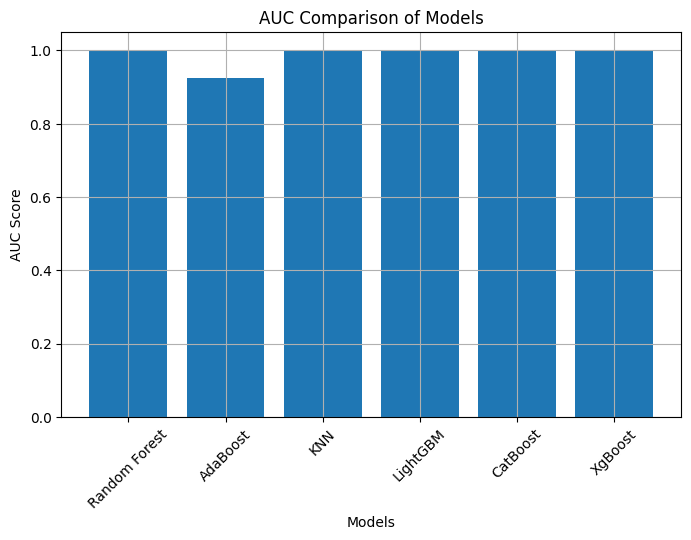

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelEncoder

# encode labels
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

auc_scores = []
for model, name in zip(models, names):

    # select correct dataset
    if model in [svm, knn]:
        X_tr, X_te = X_train_scaled, X_test_scaled
    else:
        X_tr, X_te = X_train, X_test

    # train with encoded labels
    model.fit(X_tr, y_train_enc)

    # get probabilities
    try:
        y_prob = model.predict_proba(X_te)
        auc = roc_auc_score(y_test_enc, y_prob, multi_class="ovr")
    except:
        auc = np.nan

    auc_scores.append(auc)

# plot
plt.figure(figsize=(8, 5))

plt.bar(names, auc_scores)

plt.xlabel("Models")
plt.ylabel("AUC Score")
plt.title("AUC Comparison of Models")
plt.xticks(rotation=45)
plt.grid()

plt.savefig("auc_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

**Artificial Neural Network**

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv")
y_test = pd.read_csv("y_test.csv")

In [ ]:
le = LabelEncoder()
X_train_scaled = MinMaxScaler().fit_transform(X_train)
X_test_scaled = MinMaxScaler().fit_transform(X_test)

In [ ]:
# How to buid ANN
model = Sequential()

model.add(Dense(64, activation='relu', input_dim=7))
model.add(Dense(32, activation='relu'))
model.add(Dense(23, activation='softmax'))

# compile
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# train
model.fit(X_train_scaled, to_categorical(le.fit_transform(y_train)), epochs=300, batch_size=16)



Epoch 1/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.1838 - loss: 2.9825
Epoch 2/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3883 - loss: 2.4266
Epoch 3/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6323 - loss: 1.6631
Epoch 4/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7760 - loss: 1.0924
Epoch 5/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8373 - loss: 0.7693
Epoch 6/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8639 - loss: 0.5958
Epoch 7/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8867 - loss: 0.4879
Epoch 8/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9203 - loss: 0.4068
Epoch 9/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9230 - loss: 0.3539
Epoch 10/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9328 - loss: 0.3141
Epoch 11/300
116/116 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9447 - loss: 0.2756
Epoch 12/300
116/116 ━━━━━━━━━━━━━━━━━━━

In [ ]:
model = Sequential()

model.add(Dense(128, activation='relu', input_dim=7))
model.add(Dropout(0.3))

model.add(Dense(64, activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(32, activation='relu'))

model.add(Dense(23, activation='softmax'))

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

In [ ]:
history = model.fit(X_train_scaled, to_categorical(le.fit_transform(y_train)),
    epochs=350,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.0931 - loss: 3.0761 - val_accuracy: 0.1152 - val_loss: 2.9050
Epoch 2/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2267 - loss: 2.5937 - val_accuracy: 0.3770 - val_loss: 2.0520
Epoch 3/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4233 - loss: 1.8101 - val_accuracy: 0.6963 - val_loss: 1.2479
Epoch 4/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5629 - loss: 1.2997 - val_accuracy: 0.7330 - val_loss: 0.9035
Epoch 5/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6389 - loss: 1.0524 - val_accuracy: 0.8115 - val_loss: 0.7004
Epoch 6/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6966 - loss: 0.8577 - val_accuracy: 0.8613 - val_loss: 0.5708
Epoch 7/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7267 - loss: 0.7815 - val_accuracy: 0.8743 - val_loss: 0.5165
Epoch 8/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7379 - loss: 0.7048 - val_accuracy: 0.8455 - 

In [ ]:
loss, accuracy = model.evaluate(X_test_scaled, to_categorical(le.fit_transform(y_test)))

print("Test Accuracy:", accuracy)

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9581 - loss: 0.1146
Test Accuracy: 0.9580712914466858


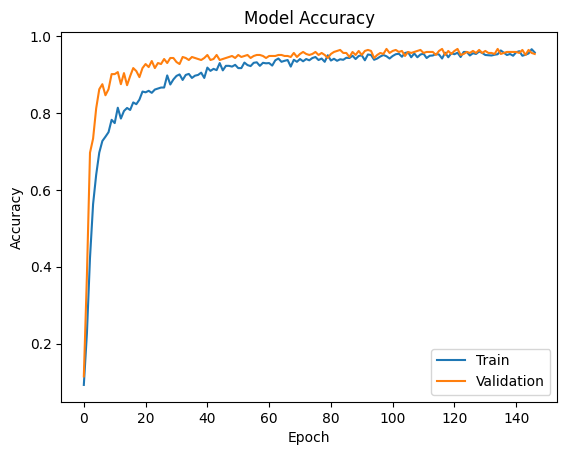

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(["Train","Validation"])

# Save the figure
plt.savefig("model_accuracy.png", dpi=300, bbox_inches="tight")

plt.show()

In [ ]:
import numpy as np

avg_train_acc = np.mean(history.history['accuracy'])

print("Average Training Accuracy:", avg_train_acc)

Average Training Accuracy: 0.8991271457603188


In [ ]:
best_val_acc = max(history.history['val_accuracy'])

print("Best Validation Accuracy:", best_val_acc)

Best Validation Accuracy: 0.9659686088562012


In [ ]:
best_epoch = np.argmax(history.history['val_accuracy'])

print("Best Epoch:", best_epoch)
print("Train Accuracy at Best Epoch:", history.history['accuracy'][best_epoch])

Best Epoch: 98
Train Accuracy at Best Epoch: 0.9469200372695923


In [ ]:
# Best validation accuracy
best_val_acc = max(history.history['val_accuracy'])
best_epoch = np.argmax(history.history['val_accuracy']) + 1

# Best training accuracy
best_train_acc = max(history.history['accuracy'])

print("Best Validation Accuracy:", best_val_acc)
print("Best Epoch:", best_epoch)
print("Best Training Accuracy:", best_train_acc)

Best Validation Accuracy: 0.9659686088562012
Best Epoch: 99
Best Training Accuracy: 0.9652686715126038


# **Attention Based Bi-LSTM**

In [ ]:
X_train_lstm = X_train_scaled.values.reshape(
    X_train_scaled.shape[0],
    X_train_scaled.shape[1],
    1
)

In [ ]:
X_test_lstm = X_test_scaled.values.reshape(
    X_test_scaled.shape[0],
    X_test_scaled.shape[1],
    1
)

In [ ]:
from tensorflow.keras.layers import (
    Input,
    Bidirectional,
    LSTM,
    Dense,
    Dropout,
    Attention,
    GlobalAveragePooling1D
)
from tensorflow.keras.models import Model

inputs = Input(shape=(7, 1))

# Bi-LSTM
x = Bidirectional(
    LSTM(64, return_sequences=True)
)(inputs)

x = Dropout(0.3)(x)

# Self-attention
attention_output = Attention()([x, x])

# Pooling
x = GlobalAveragePooling1D()(attention_output)

# Dense layers
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)

outputs = Dense(23, activation='softmax')(x)

model = Model(inputs, outputs)

model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

model.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 7, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 7, 128)    │     33,792 │ input_layer_2[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 7, 128)    │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention           │ (None, 7, 128)    │          0 │ dropout_2[0][0],  │
│ (Attention)         │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ attention[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 64)        │      8,256 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 23)        │      1,495 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 43,543 (170.09 KB)

 Trainable params: 43,543 (170.09 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train_lstm,
    to_categorical(le.fit_transform(y_train)),
    epochs=350,
    batch_size=16,
    validation_split=0.2
    #callbacks=[early_stop]
)

Epoch 1/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.0983 - loss: 2.9777 - val_accuracy: 0.0707 - val_loss: 2.8857
Epoch 2/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.1048 - loss: 2.8213 - val_accuracy: 0.1230 - val_loss: 2.7005
Epoch 3/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.1180 - loss: 2.6614 - val_accuracy: 0.1387 - val_loss: 2.5094
Epoch 4/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.1448 - loss: 2.5571 - val_accuracy: 0.1649 - val_loss: 2.3833
Epoch 5/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.1415 - loss: 2.4703 - val_accuracy: 0.2042 - val_loss: 2.3202
Epoch 6/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1658 - loss: 2.4022 - val_accuracy: 0.2382 - val_loss: 2.2098
Epoch 7/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2025 - loss: 2.3199 - val_accuracy: 0.2592 - val_loss: 2.1057
Epoch 8/350
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2379 - loss: 2.2175 - val_accuracy: 0.

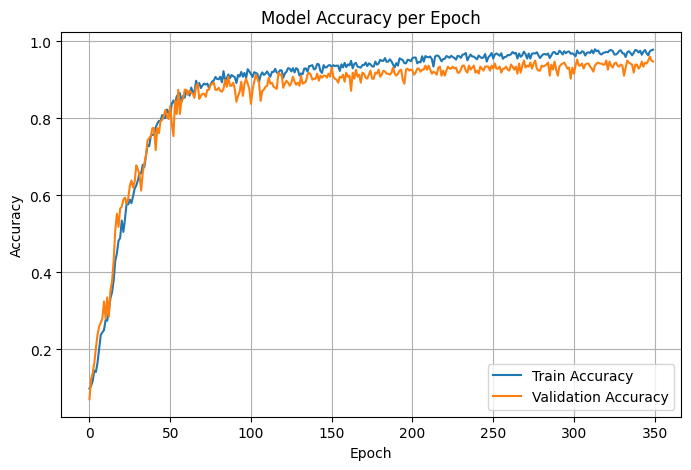

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.savefig("accuracy_curve_bi_lstm.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
loss, accuracy = model.evaluate(X_test_lstm, to_categorical(le.fit_transform(y_test)))

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9350 - loss: 0.2257


In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.layers import Bidirectional, LSTM, GlobalAveragePooling1D, MultiHeadAttention

inputs = Input(shape=(7, 1))

# BiLSTM
x = Bidirectional(LSTM(64, return_sequences=True))(inputs)
x = Dropout(0.3)(x)

# Attention
attn = MultiHeadAttention(num_heads=4, key_dim=32)(x, x)

# Pooling
x = GlobalAveragePooling1D()(attn)

# Dense layers
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x)

outputs = Dense(23, activation='softmax')(x)

model = Model(inputs, outputs)

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 7, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 7, 128)    │     33,792 │ input_layer_3[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 7, 128)    │          0 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 7, 128)    │     66,048 │ dropout_4[0][0],  │
│ (MultiHeadAttentio… │                   │            │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ multi_head_atten… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 64)        │      8,256 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64)        │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 23)        │      1,495 │ dropout_6[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 109,591 (428.09 KB)

 Trainable params: 109,591 (428.09 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train_lstm,
    to_categorical(le.fit_transform(y_train)),
    validation_split=0.2,
    epochs=300,
    batch_size=16
    #,callbacks=[early_stop]
)

Epoch 1/300
96/96 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - accuracy: 0.8827 - loss: 0.2937 - val_accuracy: 0.8979 - val_loss: 0.2821
Epoch 2/300
96/96 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.8873 - loss: 0.3096 - val_accuracy: 0.8927 - val_loss: 0.2687
Epoch 3/300
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.8847 - loss: 0.3321 - val_accuracy: 0.8743 - val_loss: 0.3229
Epoch 4/300
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8866 - loss: 0.3210 - val_accuracy: 0.8613 - val_loss: 0.3606
Epoch 5/300
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8873 - loss: 0.2948 - val_accuracy: 0.8560 - val_loss: 0.3722
Epoch 6/300
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.8952 - loss: 0.2837 - val_accuracy: 0.8953 - val_loss: 0.3272
Epoch 7/300
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.8794 - loss: 0.3257 - val_accuracy: 0.8953 - val_loss: 0.2617
Epoch 8/300
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8906 - loss: 0.3149 - val_accuracy: 0.

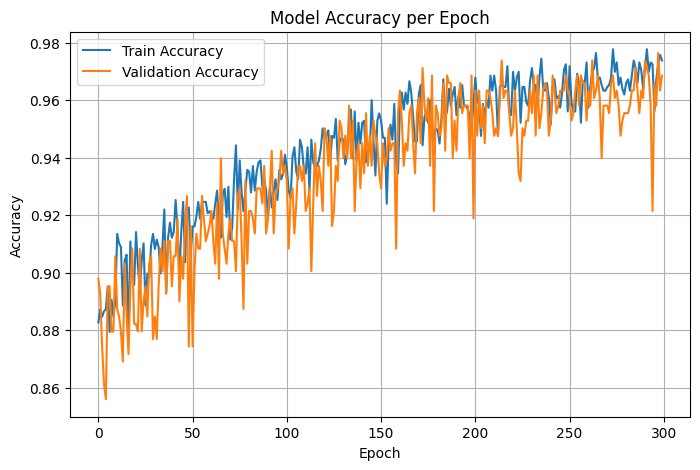

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("Model Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.savefig("accuracy_curve_bi_lstm_multiattention.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
loss, accuracy = model.evaluate(X_test_lstm, to_categorical(le.fit_transform(y_test)))

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9623 - loss: 0.1302
